# Кластеризация штаммов бактерий по множеству признаков

Задача 5 курса «Технологии искусственного интеллекта в биоэкономике».

20 штаммов, семь признаков трёх разных типов: пять количественных, один бинарный
(наличие плазмиды) и один категориальный (источник выделения). Нужно построить
смешанную матрицу расстояний, определить число кластеров автоматически и
визуализировать результат.

Вся логика живёт в пакете `src/`, ноутбук её вызывает и показывает результаты.
Подробности решений — в [docs/PIPELINE.md](../docs/PIPELINE.md).


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)


## 1. Данные

Используется набор с заложенной структурой из трёх экотипов. Данные из условия
задачи (`np.random.uniform` по всем признакам независимо) кластерной структуры не
содержат — это однородное облако, в котором находить нечего; они оставлены как
контрольный набор `strains_uniform.csv`.

Настоящий экотип каждого штамма хранится отдельно и **в кластеризацию не подаётся** —
только для проверки качества разбиения.


In [2]:
from src.loader import load_strains, load_truth

df = load_strains(ROOT / 'data' / 'strains_features.csv')
truth = load_truth(ROOT / 'data' / 'strains_truth.csv')

print(f'Штаммов: {len(df)}, источники: {df.source.value_counts().to_dict()}')
df


Штаммов: 20, источники: {'gut': 8, 'soil': 6, 'water': 6}


,strain_id,growth_rate,product_yield,pH_tolerance,GC_content,genome_size_mbp,has_plasmid,source
0,S01,1.264,2.46,6.20,50.20,3.974,0,gut
1,S02,1.073,2.03,5.76,47.12,3.779,1,gut
2,S03,0.583,3.52,8.14,56.23,5.297,0,soil
3,S04,1.330,2.11,5.96,51.44,3.983,1,gut
4,S05,1.190,3.17,5.99,62.07,3.464,1,water
5,S06,1.106,3.13,5.86,58.06,4.205,0,water
6,S07,1.205,3.63,5.72,58.48,3.450,1,gut
7,S08,0.991,3.58,8.15,61.22,5.480,0,soil
8,S09,1.118,3.13,6.11,60.07,3.935,0,water
9,S10,1.064,1.69,6.47,49.01,3.192,1,gut


## 2. Предобработка

Количественные признаки стандартизуются (вычесть среднее, разделить на стандартное
отклонение), источник кодируется one-hot по трём категориям. Первая категория **не**
отбрасывается: при полной кодировке евклидово расстояние одинаково для любой пары
различных категорий, а при усечённой одна категория оказывается ближе к остальным
без всякого основания.

Признаки не склеиваются в одну матрицу: дальше их обрабатывают разные метрики.


In [3]:
from src.preprocess import build_blocks

blocks = build_blocks(df)
print(f'Количественные: {blocks.quantitative.shape}, бинарный: {blocks.binary.shape}, категориальный: {blocks.categorical.shape}')
pd.DataFrame(blocks.quantitative, index=blocks.strain_ids, columns=blocks.quant_names).round(2).head()


Количественные: (20, 5), бинарный: (20, 1), категориальный: (20, 3)


,growth_rate,product_yield,pH_tolerance,GC_content,genome_size_mbp
S01,0.95,-0.83,-0.76,-1.19,-0.34
S02,0.12,-1.51,-1.25,-1.82,-0.59
S03,-1.99,0.84,1.41,0.04,1.36
S04,1.23,-1.38,-1.03,-0.94,-0.33
S05,0.63,0.29,-0.99,1.23,-0.99


## 3. Смешанная матрица расстояний

Схема из условия: евклидово расстояние по количественным, Хэмминга по бинарному,
евклидово по one-hot. Каждая компонента нормируется на свой максимум, затем
складывается с весами 0.6 / 0.2 / 0.2.

Сразу смотрим на устройство компонент — от него зависит всё остальное.


In [4]:
from src.distances import mixed_distance

parts = mixed_distance(blocks)
off = ~np.eye(len(df), dtype=bool)

for name in ('quantitative', 'binary', 'categorical'):
    values = np.unique(np.round(getattr(parts, name)[off], 6))
    note = '  <- ступенчатая' if len(values) <= 2 else ''
    print(f'{name:14s} различных значений на 190 парах: {len(values):3d}{note}')


quantitative   различных значений на 190 парах: 190
binary         различных значений на 190 парах:   2  <- ступенчатая
categorical    различных значений на 190 парах:   2  <- ступенчатая


Две компоненты из трёх принимают ровно два значения, 0 и 1. Хэмминг по одному
бинарному признаку иначе и не может, евклид по one-hot из трёх категорий даёт либо 0,
либо корень из двух. После нормировки обе вырождаются в ступеньку.

**Следствие: 40% итогового расстояния не несут непрерывной геометрии.** Её задают
исключительно пять количественных признаков с весом 0.6. К этому вернёмся в разделе 7 —
там выяснится, что это и определяет результат.


In [5]:
distance = parts.mixed
pd.DataFrame(distance, index=df.strain_id, columns=df.strain_id).round(2).iloc[:8, :8]


strain_id,S01,S02,S03,S04,S05,S06,S07,S08
strain_id,,,,,,,,
S01,0.00,0.36,0.72,0.28,0.72,0.44,0.50,0.69
S02,0.36,0.00,0.97,0.17,0.61,0.73,0.40,0.99
S03,0.72,0.97,0.00,0.97,0.91,0.63,0.92,0.24
S04,0.28,0.17,0.97,0.00,0.53,0.67,0.34,0.93
S05,0.72,0.61,0.91,0.53,0.00,0.35,0.32,0.83
S06,0.44,0.73,0.63,0.67,0.35,0.00,0.55,0.57
S07,0.50,0.40,0.92,0.34,0.32,0.55,0.00,0.85
S08,0.69,0.99,0.24,0.93,0.83,0.57,0.85,0.00


## 4. Кластеризация и подбор числа кластеров

Иерархическая кластеризация методом Уорда, число кластеров — по максимуму индекса
силуэта среди k от 2 до 10. Силуэт считается на той же матрице, по которой строилось
дерево.

Оговорка о методе: формула Уорда предполагает евклидову метрику, а взвешенная смесь
трёх расстояний ею не является. Задание требует именно Уорда, поэтому он и используется,
но параллельно прогоняется average linkage, для которого произвольная матрица корректна.


In [6]:
from src.clustering import cluster
from sklearn.metrics import adjusted_rand_score

result = cluster(distance)
control = cluster(distance, method='average')

print('Силуэт по k:')
for k, score in result.scores.items():
    mark = '  <- максимум' if k == result.best_k else ''
    print(f'  k={k:2d}  {score:.3f}{mark}')
print()
print(f'Оптимальное k = {result.best_k}, силуэт {result.silhouette:.3f}')
print(f'Размеры кластеров: {result.cluster_sizes}')
print(f'Контроль average linkage: k = {control.best_k}, совпадение с Уордом '
      f'ARI = {adjusted_rand_score(result.labels, control.labels):.2f}')


Силуэт по k:
  k= 2  0.490
  k= 3  0.494  <- максимум
  k= 4  0.470
  k= 5  0.492
  k= 6  0.466
  k= 7  0.456
  k= 8  0.443
  k= 9  0.436
  k=10  0.395

Оптимальное k = 3, силуэт 0.494
Размеры кластеров: {1: 6, 2: 7, 3: 7}
Контроль average linkage: k = 3, совпадение с Уордом ARI = 1.00


In [7]:
print(f'Неотличимые по силуэту k: {result.plateau}')
print(f'Число кластеров определено однозначно: {result.is_conclusive}')


Неотличимые по силуэту k: (2, 3, 5)
Число кластеров определено однозначно: False


**Максимум силуэта здесь ничего не решает.** Профиль почти плоский: 0.490 при k=2,
0.494 при k=3, 0.492 при k=5. Разрыв между первым и вторым местом — 0.004, на 20
объектах это шум. Поэтому `is_conclusive` равно `False`, и argmax нельзя подавать как
найденный ответ.


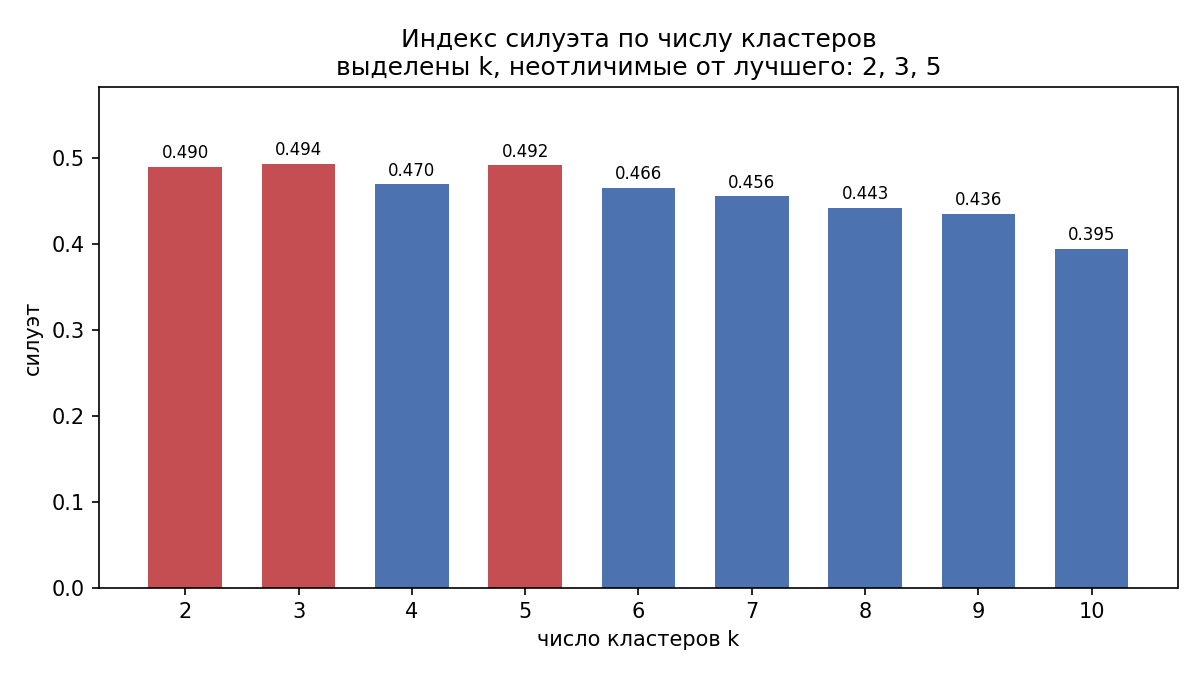

In [8]:
from src.viz import plot_silhouette_profile
from IPython.display import Image, display

out = ROOT / 'out'
out.mkdir(exist_ok=True)
display(Image(str(plot_silhouette_profile(result.scores, result.best_k,
                                          out / 'silhouette_profile.png', result.plateau))))


## 5. Отличается ли структура от случайной

Силуэт — описательная мера, у него нет нулевого распределения. На 20 объектах его
максимум по k почти всегда оказывается приличным: на 300 независимых равномерных
наборах медиана составила 0.307, а 95-й процентиль 0.368. Без нулевого распределения
«силуэт высокий» ничего не означает.

Нулевая модель — независимое перемешивание каждого столбца. Оно рвёт связи между
признаками, сохраняя их распределения, то есть проверяет наличие именно многомерной
структуры.


In [9]:
from src.significance import assess

significance = assess(df, result.silhouette, n_draws=200)
print(significance.summary())


силуэт 0.494 против нулевого распределения (медиана 0.303, максимум 0.419, 200 перестановок): процентиль 100.0, p = 0.0050 - структура значимо отличается от случайной


In [10]:
figure, axes = plt.subplots(figsize=(8, 4))
axes.hist(significance.null_scores, bins=30, color='#8C8C8C', label='перестановки')
axes.axvline(significance.observed, color='#C44E52', linewidth=2,
             label=f'наблюдённый силуэт {significance.observed:.3f}')
axes.set_xlabel('максимум силуэта по k')
axes.set_ylabel('число перестановок')
axes.set_title('Наблюдённый силуэт на фоне нулевого распределения')
axes.legend()
plt.show()


/var/folders/ym/845x_sy54bs4qng_q9qc77wr0000gn/T/ipykernel_7018/1240626925.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6. Профили кластеров

Средние значения выводятся в исходных единицах — проценты GC и мегабазы читаются,
z-оценки нет. Доля моды источника показана отдельно: без неё «преимущественно почва»
может означать и 7 из 7, и 3 из 7.


In [11]:
from src.profiling import (agreement_with_truth, categorical_echo, cluster_summary,
                           describe_clusters, mismatched_strains)

summary = cluster_summary(df, result.labels)
summary


,cluster,n_strains,growth_rate,product_yield,pH_tolerance,GC_content,genome_size_mbp,plasmid_share,source_mode,source_mode_share,source_mix
0,1,6,0.792,3.513,7.988,59.707,5.279,0.00,soil,1.00,soil 6
1,2,7,1.145,2.261,6.536,51.271,3.890,0.86,gut,1.00,gut 7
2,3,7,1.160,3.266,6.276,57.643,3.696,0.57,water,0.86,"water 6, gut 1"


In [12]:
print(describe_clusters(summary))


Кластер 1: 6 штаммов. growth_rate 0.79, product_yield 3.51, pH_tolerance 7.99, GC_content 59.71, genome_size_mbp 5.28. Плазмида у 0%. Источник преимущественно soil (100%; состав: soil 6).
Кластер 2: 7 штаммов. growth_rate 1.15, product_yield 2.26, pH_tolerance 6.54, GC_content 51.27, genome_size_mbp 3.89. Плазмида у 86%. Источник преимущественно gut (100%; состав: gut 7).
Кластер 3: 7 штаммов. growth_rate 1.16, product_yield 3.27, pH_tolerance 6.28, GC_content 57.64, genome_size_mbp 3.70. Плазмида у 57%. Источник преимущественно water (86%; состав: water 6, gut 1).


### Не пересказывают ли кластеры просто категориальные признаки

Две ступенчатые компоненты дают 40% веса, поэтому разбиение может оказаться
пересказом источника и плазмиды. Это надо измерить, а не предположить.


In [13]:
echo = categorical_echo(df, result.labels)
agreement = agreement_with_truth(truth, result.labels)

print('Совпадение разбиения (ARI):')
print(f'  с заявленным источником      {echo["source_only"]:.2f}')
print(f'  с наличием плазмиды          {echo["plasmid_only"]:.2f}')
print(f'  с комбинацией источник x плазмида  {echo["source_x_plasmid"]:.2f}')
print(f'  с настоящим экотипом         {agreement["ari"]:.2f}')
print()
print(agreement['crosstab'])


Совпадение разбиения (ARI):
  с заявленным источником      0.84
  с наличием плазмиды          0.26
  с комбинацией источник x плазмида  0.63
  с настоящим экотипом         0.70

cluster  1  2  3
ecotype         
gut      0  6  1
soil     6  1  0
water    0  0  6


**Разбиение ближе к заявленному источнику (0.84), чем к настоящему экотипу (0.70).**
Проверим это на штаммах, у которых источник намеренно не совпадает с экотипом: если
количественные признаки с весом 0.6 действительно перевешивают категорию с весом 0.2,
такой штамм должен попасть в кластер своего экотипа.


In [14]:
mismatched = mismatched_strains(df, truth, result.labels)
print(f'За настоящим экотипом пошли {int(mismatched.followed_ecotype.sum())} из {len(mismatched)}')
mismatched


За настоящим экотипом пошли 1 из 3


,strain_id,ecotype,source,cluster,cluster_ecotype,followed_ecotype
0,S07,water,gut,3,water,True
1,S13,soil,gut,2,gut,False
2,S16,gut,water,3,water,False


## 7. Устойчивость к выбору весов — главный результат

Веса 0.6 / 0.2 / 0.2 заданы в условии без обоснования. Проверим, насколько от них
зависит ответ.

Сначала — почему категория вообще способна перевесить пять количественных признаков.


In [15]:
from src.sensitivity import separating_gap, sweep, tipping_point

gap = separating_gap(blocks, truth.ecotype)
print(f'Медиана расстояния внутри экотипа:  {gap["median_within_group"]}')
print(f'Медиана расстояния между экотипами: {gap["median_between_groups"]}')
print(f'Разделяющий разрыв:                 {gap["separating_gap"]}')
print()
print(f'Плоский штраф за несовпадение источника: 0.200')
print(f'Это {0.2 / gap["separating_gap"]:.0%} всей разделяющей способности пяти количественных признаков.')
print(f'Два плоских штрафа вместе: 0.400, то есть {0.4 / gap["separating_gap"]:.1f} разрыва.')


Медиана расстояния внутри экотипа:  0.153
Медиана расстояния между экотипами: 0.418
Разделяющий разрыв:                 0.265

Плоский штраф за несовпадение источника: 0.200
Это 75% всей разделяющей способности пяти количественных признаков.
Два плоских штрафа вместе: 0.400, то есть 1.5 разрыва.


In [16]:
table = sweep(blocks, df, truth)
table


,quantitative,binary,categorical,best_k,silhouette,ari_vs_ecotype,ari_vs_source,is_assignment
0,1.0,0.00,0.00,3,0.536,1.00,0.56,False
1,0.9,0.05,0.05,3,0.528,1.00,0.56,False
2,0.8,0.10,0.10,3,0.517,1.00,0.56,False
3,0.7,0.15,0.15,3,0.499,1.00,0.56,False
4,0.6,0.20,0.20,3,0.494,0.70,0.84,True
5,0.5,0.25,0.25,3,0.570,0.56,1.00,False
6,0.4,0.30,0.30,4,0.628,0.50,0.88,False


In [17]:
print(tipping_point(table))


экотипы восстанавливаются полностью при весе категориальных признаков до 0.15; на весах из задания (0.20) совпадение падает до 0.70, а совпадение с заявленным источником составляет 0.84


Три вывода из этой таблицы.

**Веса из задания стоят на точке перелома.** При весе категориальных признаков 0.15 и
ниже экотипы восстанавливаются полностью (ARI 1.00). На весах задания совпадение падает
до 0.70, а при 0.25 разбиение становится дословным пересказом источника.

**Силуэт не является мерой правильности.** При весах 0.5 / 0.25 / 0.25 силуэт выше
(0.570 против 0.494), а совпадение с настоящими экотипами хуже (0.56 против 0.70).
Подбор весов по максимуму силуэта ухудшил бы ответ.

**Причина — в ступенчатости.** Плоский штраф не зависит от того, насколько штаммы
похожи на самом деле: любое несовпадение источника стоит ровно 0.2, тогда как весь
разрыв между экотипами по пяти непрерывным признакам — 0.265.


## 8. Визуализация

Три представления отвечают на разные вопросы.

Дендрограмма показывает иерархию и то, насколько произволен разрез.

PCA требует задание. Важная оговорка: PCA работает с признаками, а кластеры построены
по взвешенной матрице — это разные геометрии, и кластеры на PCA могут выглядеть
перемешанными при корректном разбиении.

MDS проецирует ровно ту матрицу, по которой кластеризовали, поэтому именно он —
честная картинка разбиения.


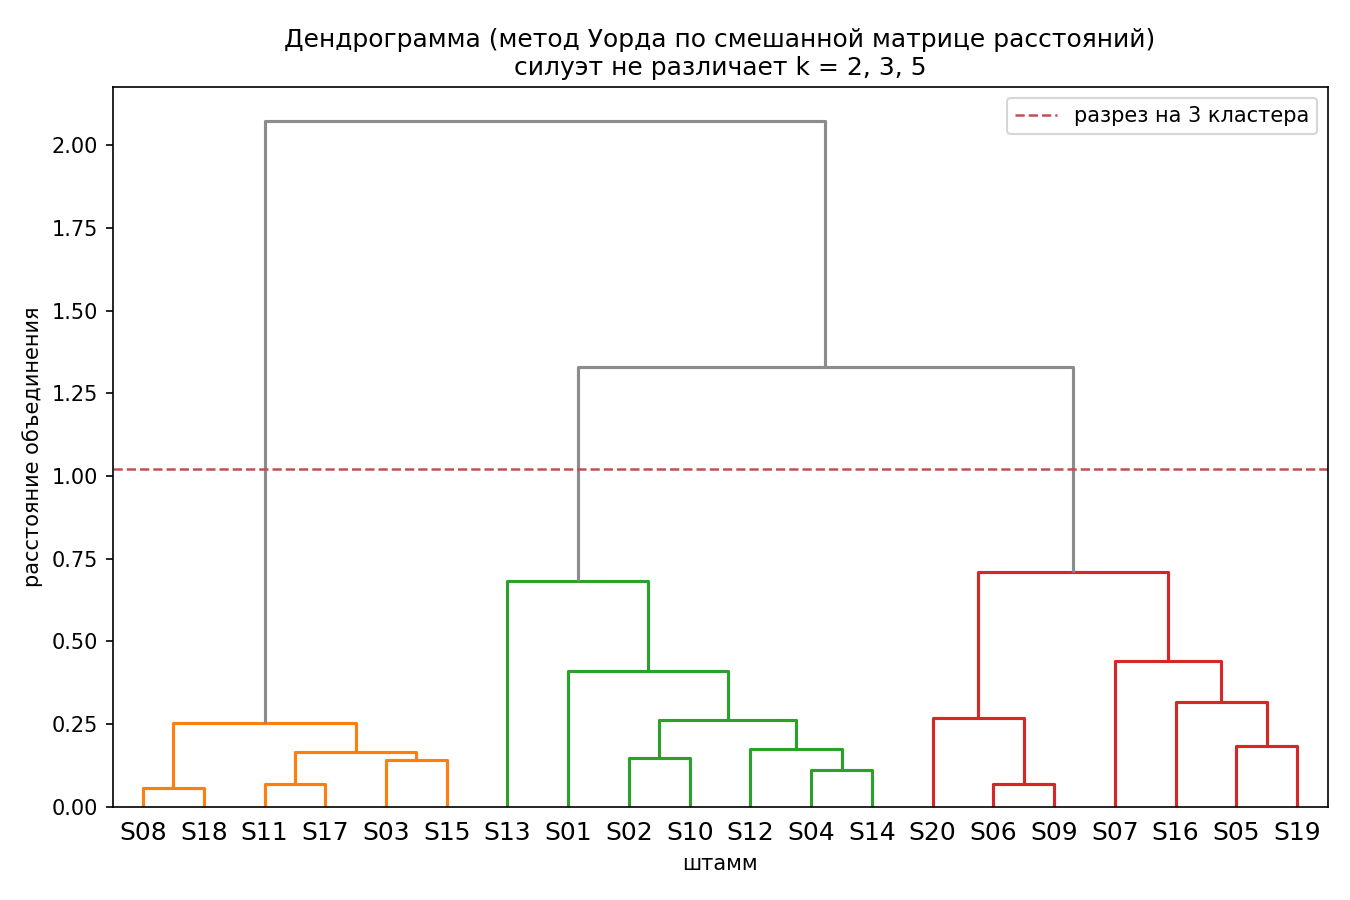

In [18]:
from src.viz import (coordinates_table, describe_projection, mds_coordinates,
                     pca_coordinates, plot_dendrogram, plot_projection)

display(Image(str(plot_dendrogram(result.tree, blocks.strain_ids, result.best_k,
                                  out / 'dendrogram.png', result.plateau))))


Первые две компоненты объясняют 86.7% дисперсии
Напряжение MDS (Краскал, stress-1): 0.110


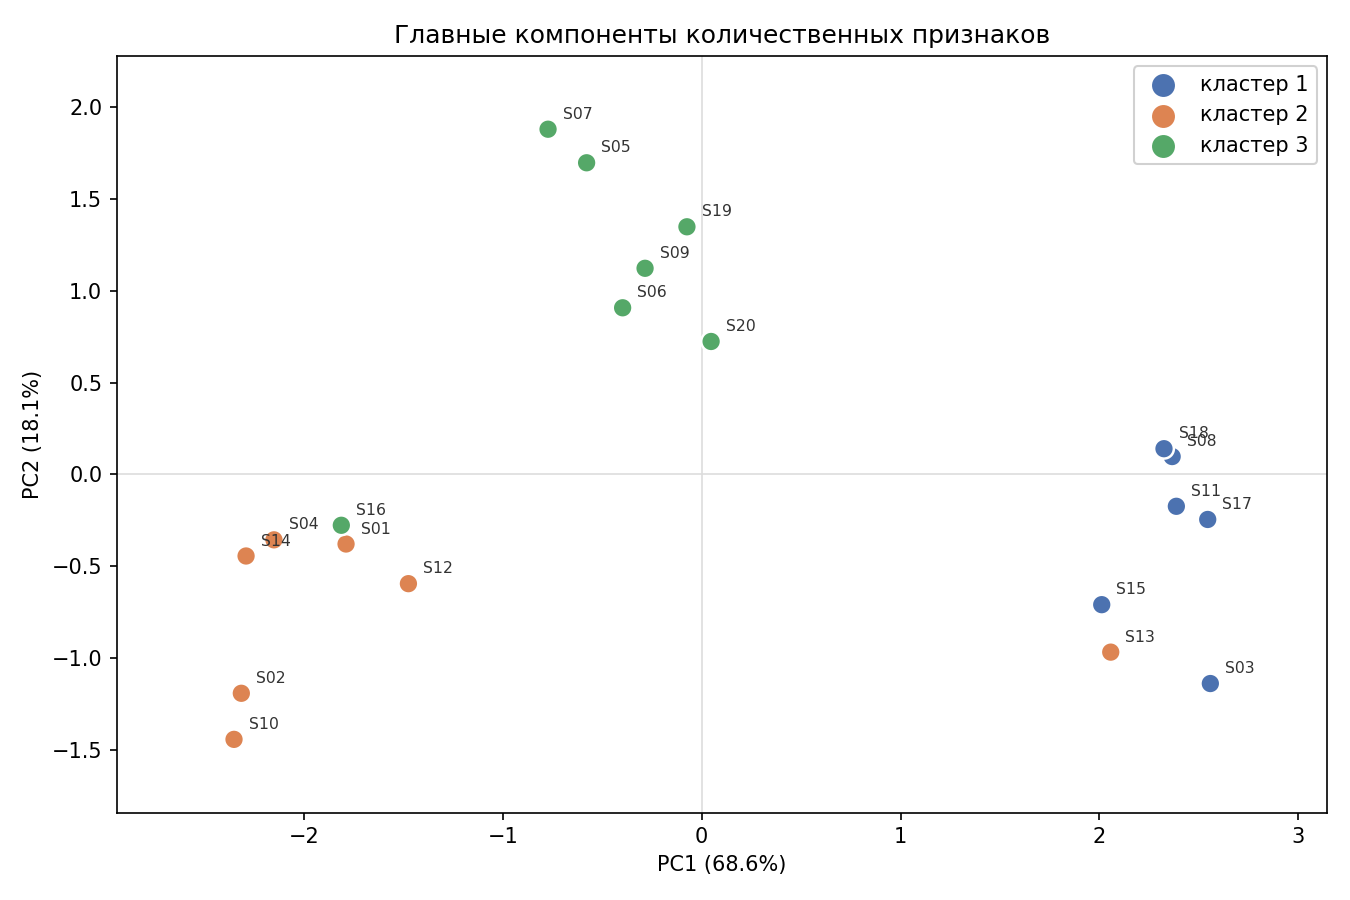

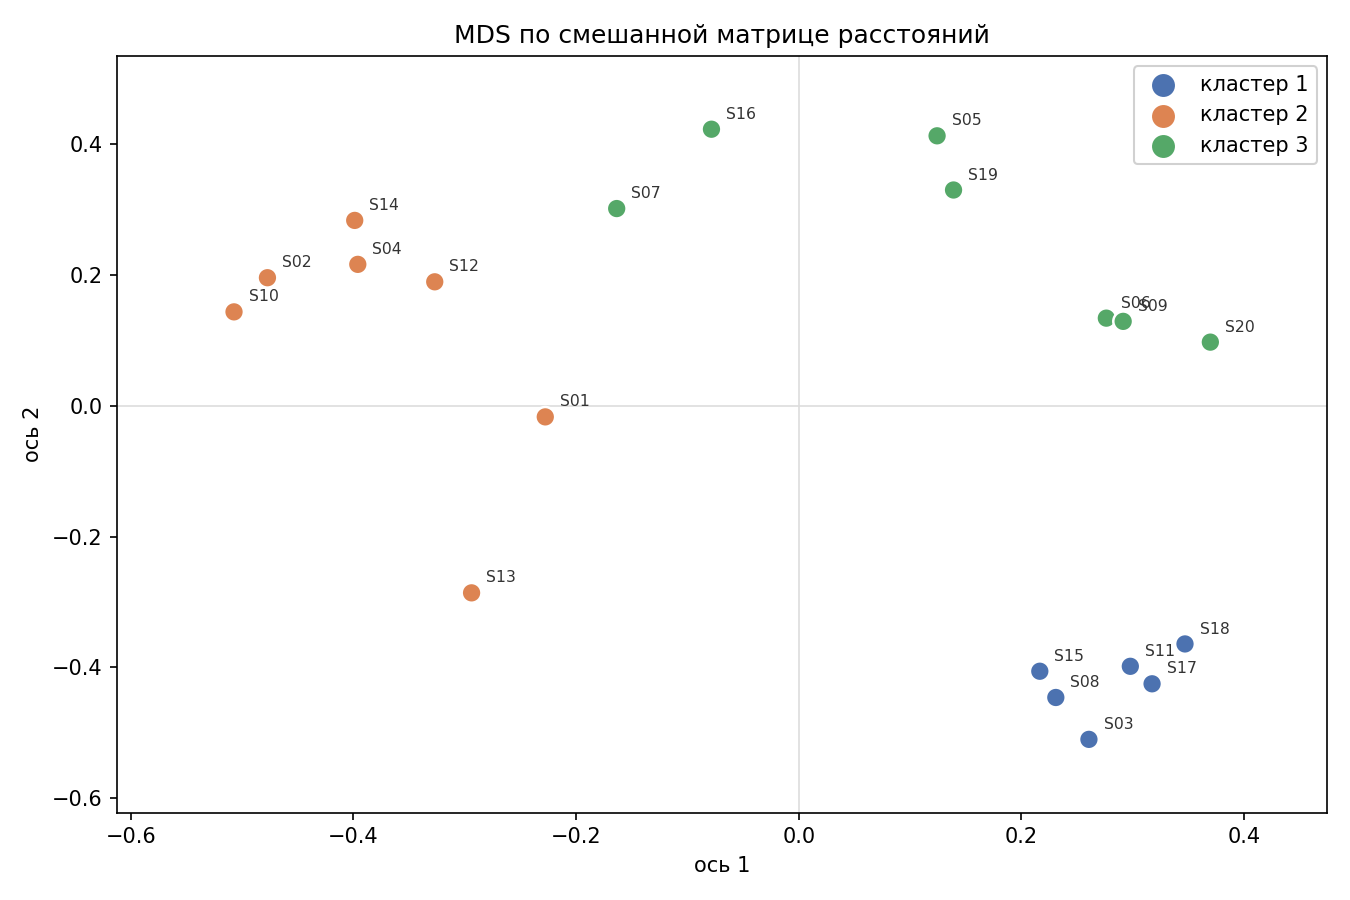

In [19]:
pca, variance = pca_coordinates(blocks)
mds, stress = mds_coordinates(distance)

print(f'Первые две компоненты объясняют {variance.sum() * 100:.1f}% дисперсии')
print(f'Напряжение MDS (Краскал, stress-1): {stress:.3f}')

display(Image(str(plot_projection(pca, result.labels, blocks.strain_ids,
                                  out / 'pca_scatter.png',
                                  'Главные компоненты количественных признаков',
                                  (f'PC1 ({variance[0] * 100:.1f}%)',
                                   f'PC2 ({variance[1] * 100:.1f}%)')))))
display(Image(str(plot_projection(mds, result.labels, blocks.strain_ids,
                                  out / 'mds_scatter.png',
                                  'MDS по смешанной матрице расстояний',
                                  ('ось 1', 'ось 2')))))


Текстовое описание проекции — на случай, если графика недоступна.


In [20]:
print(describe_projection(pca, result.labels, blocks.strain_ids, variance))


Первые две компоненты объясняют 86.7% дисперсии (68.6% и 18.1%).
Кластер 1: центр (+2.36, -0.34), штаммы S03, S08, S11, S15, S17, S18.
Кластер 2: центр (-1.47, -0.77), штаммы S01, S02, S04, S10, S12, S13, S14.
Кластер 3: центр (-0.55, +1.06), штаммы S05, S06, S07, S09, S16, S19, S20.


In [21]:
coordinates, _ = coordinates_table(blocks, distance)
coordinates.to_csv(out / 'pca_coordinates.csv', index=False)
coordinates.head()


,strain_id,pc1,pc2,mds1,mds2
0,S01,-1.7884,-0.3790,-0.2277,-0.0171
1,S02,-2.3149,-1.1924,-0.4772,0.1955
2,S03,2.5573,-1.1393,0.2606,-0.5099
3,S04,-2.1508,-0.3563,-0.3961,0.2159
4,S05,-0.5788,1.6984,0.1242,0.4123


## Выводы

**Требуемые результаты.** Оптимальное число кластеров 3, силуэт 0.494, размеры 6 / 7 / 7.
Принадлежность штаммов — в `out/clusters.csv`, профили кластеров — в
`out/cluster_summary.csv`, координаты проекций — в `out/pca_coordinates.csv`.

**Три оговорки, без которых результат легко перетолковать.**

Число кластеров определено неустойчиво: силуэт не различает k = 2, 3 и 5, разрыв между
ними 0.004. Утверждать «кластеров ровно три» на основании максимума силуэта нельзя —
k = 3 выбрано argmax'ом, но подтверждается оно совпадением с заложенной структурой, а не
самим силуэтом.

Структура значимо отличается от случайной (p = 0.005 по перестановочному тесту), и это
утверждение проверяемое — в отличие от «силуэт высокий», которое на 20 объектах не
значит ничего: на чистом шуме силуэт доходит до 0.42.

Схема взвешивания из условия отдаёт решающую роль категориальному признаку. Один
плоский штраф за несовпадение источника стоит 75% всей разделяющей способности пяти
количественных признаков. Из трёх штаммов с ложной меткой источника за своим настоящим
экотипом пошёл только один. При весе категориальных признаков 0.15 вместо 0.20 экотипы
восстанавливаются полностью.

**Практический вывод.** При смешивании признаков разных типов вес компоненты — это не
то же самое, что её влияние. Ступенчатая компонента с весом 0.2 влияет сильнее, чем
непрерывная с весом 0.6, потому что она всегда срабатывает на полную величину, а
непрерывная — пропорционально реальному различию. Нормировка на максимум это не
исправляет, а усугубляет: она растягивает двузначную компоненту на весь отрезок [0, 1].
